In [1]:
from ultralytics import YOLO
import os
import matplotlib.pyplot as plt
import gc
import torch
import os
import sys
sys.path.insert(0, os.path.abspath(os.path.join("..")))
from pipeline.preprocessing.steps import BackgroundEraser
import glob
from pipeline.feature_learning.steps import VAE
from PIL import Image
from torchvision import transforms
from pipeline.feature_learning.steps import resize_with_padding


In [ ]:
# pretrained segmentation model
model = YOLO("../models/yolov8n_seg_finetuned.pt")  # n/s/m/l/x méretek

In [ ]:

image_paths = glob.glob("/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot/**/*.jpg", recursive=True)[:500]

print(f"Found {len(image_paths)} images.")

br=BackgroundEraser(image_paths=image_paths)

br.run()

Found 1000 images.


In [ ]:
vae = VAE(f=4, n=3, s=1, k=128)  # k=128 latent dimension
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vae.to(device)

vae.train_model(
    folder="/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot", 
    epochs=1000, 
    lr=1e-5,      
    batch_size=128
)

# latent_vectors = vae.extract_features(
#     folder="/caa/Homes01/alaczko/Diploma/Diploma/data/processed/cleared_images",
#     batch_size=32
# )

# print(latent_vectors.shape)

torch.save(vae.state_dict(), "-../models/feature_learning/new_fl_model.pt")

[epoch 1] loss: 5098108.350 | beta: 0.000
[epoch 2] loss: 5091432.000 | beta: 0.020
[epoch 3] loss: 5085109.650 | beta: 0.040
[epoch 4] loss: 5078497.250 | beta: 0.060
[epoch 5] loss: 5071892.150 | beta: 0.080
[epoch 6] loss: 5065168.550 | beta: 0.100


KeyboardInterrupt: 

[epoch 1] loss: 1353931.506
[epoch 2] loss: 1353410.569
[epoch 3] loss: 1352911.637
[epoch 4] loss: 1352423.925
[epoch 5] loss: 1351923.169
[epoch 6] loss: 1351422.119
[epoch 7] loss: 1350913.719
[epoch 8] loss: 1350395.262
[epoch 9] loss: 1349917.094
[epoch 10] loss: 1349405.206
torch.Size([304, 256])

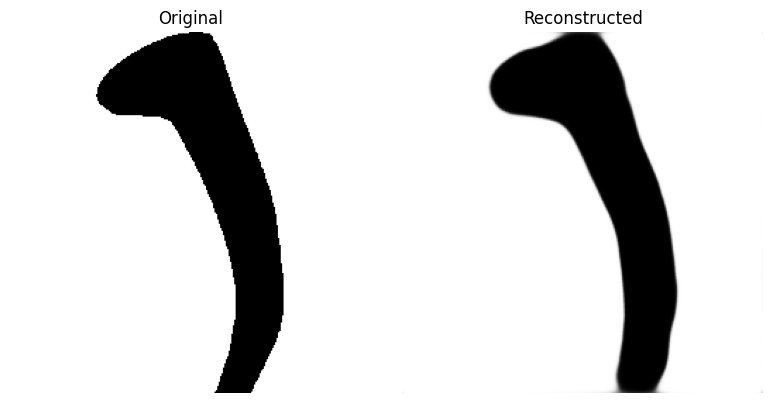

In [6]:
vae_eval=VAE(f=4, n=3, s=1, k=128)

vae_eval.load_state_dict(torch.load("new_fl_model.pt", map_location="cuda"))
vae_eval.eval()

#making sure the formula is correct
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Lambda(lambda img: resize_with_padding(img, 256)),
    transforms.ToTensor(),
])

img_path = "/caa/Homes01/alaczko/Diploma/Diploma/data/rocopot/STAN01-6.I2FF9.26.png"
original_img = Image.open(img_path)
input_tensor = transform(original_img).unsqueeze(0) #adding batch dim

with torch.no_grad():
    reconstructed, mu, sigma = vae_eval(input_tensor)

orig_np = input_tensor.squeeze().numpy()
recon_np = reconstructed.squeeze().numpy()

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(orig_np, cmap='gray', vmin=0, vmax=1)
axes[0].set_title("Original")
axes[0].axis('off')

axes[1].imshow(recon_np, cmap='gray', vmin=0, vmax=1)
axes[1].set_title("Reconstructed")
axes[1].axis('off')

plt.tight_layout()
plt.show()